# AED guiado pelo DAMICORE em um dado real: o gene DHFR

**A ideia em uma frase.** Um laboratório quer achar a sequência de DNA que deixa
uma bactéria mais resistente a um antibiótico, medindo o mínimo de sequências
possível. Usamos o AED do slide ("DAMICORE gerando modelos para AEDs") e
perguntamos duas coisas:

1. **Ele otimiza?** Acha sequências entre as melhores medindo poucas?
2. **O DAMICORE acha algo que faz sentido?** Sem que ninguém conte nada a ele,
   as posições que ele junta são as que a biologia diz que andam juntas?

**O dado.** Papkou et al. (2023, *Science*) mediram **todas** as combinações de 9
letras de DNA de um trecho do gene *folA* da *E. coli* (a enzima DHFR): 4⁹ =
262.144 sequências, 261.333 com medida. Cada uma tem um número de **fitness**:
quanto a bactéria cresce sob o antibiótico trimetoprima, comparado com a
sequência original (0 = igual à original, maior = melhor, muito negativo =
morre). Fonte: Zenodo 10.5281/zenodo.8228920, licença CC BY 4.0.

**O gabarito que o DAMICORE não vê.** As 9 letras são lidas pela célula de três
em três: posições 1-2-3, 4-5-6 e 7-8-9 são três **códons**, e cada códon vira um
aminoácido. Mudar uma letra sozinha pode não fazer sentido; o que importa é a
trinca. Se o DAMICORE juntar as posições do mesmo códon, ele descobriu sozinho
um pedaço do código genético.


/Users/erickpatrickbarcelos/codes/data-mining/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sequências medidas: 261,333
Original (GCCGATCTC): fitness 0.  Melhor de todas: 1.396
Metade das sequências tem fitness abaixo de -0.71 (bactéria morre ou quase)


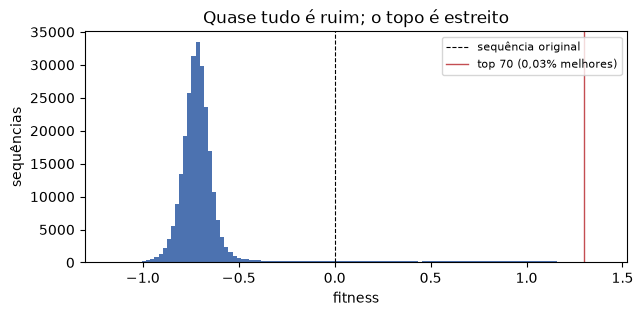

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import toytree
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while (
    PROJECT_ROOT != PROJECT_ROOT.parent
    and not (PROJECT_ROOT / "pyproject.toml").exists()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").exists():
    raise RuntimeError("Open this notebook from the repository environment.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from hypotheses.dhfr_codon_linkage.scripts.config import ARTIFACT_ROOT, DEFAULT_CONFIG
from hypotheses.dhfr_codon_linkage.scripts.experiment import CODONS, _codon_contrast, _triple_partitions
from hypotheses.dhfr_codon_linkage.scripts.landscape import load_landscape

landscape = load_landscape()
solutions, fitness = landscape.table()
print(f"Sequências medidas: {len(fitness):,}")
print(f"Original (GCCGATCTC): fitness 0.  Melhor de todas: {fitness.max():.3f}")
print(f"Metade das sequências tem fitness abaixo de {np.median(fitness):.2f} (bactéria morre ou quase)")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(fitness, bins=120, color="#4c72b0")
ax.axvline(0, color="black", lw=0.8, ls="--", label="sequência original")
ax.axvline(landscape.top_threshold(DEFAULT_CONFIG.top_k), color="#c44e52", lw=1,
           label=f"top {DEFAULT_CONFIG.top_k} (0,03% melhores)")
ax.set(xlabel="fitness", ylabel="sequências", title="Quase tudo é ruim; o topo é estreito")
ax.legend(fontsize=8)
plt.show()


## 1. O AED do slide, passo a passo

O "laboratório" mede no máximo **1.000 sequências diferentes** por execução
(0,4% de todas). Começa com 200 sequências sorteadas e repete:

1. **Seleciona** as 30% melhores (as *promissoras*).
2. **Monta um arquivo por posição.** Cada promissora ganha um código curto; o
   arquivo da posição 1 lista os códigos das que têm A ali, depois as que têm C,
   G e T. Duas posições que "separam" as sequências do mesmo jeito geram arquivos
   parecidos.
3. **DAMICORE**: compara os 9 arquivos por compressão (NCD), monta a árvore
   (Neighbor Joining) e corta em grupos (FastGreedy).
4. **Modelo**: para cada grupo, guarda as combinações de letras que aparecem nas
   promissoras e com que frequência.
5. **Gera filhos** sorteando cada grupo inteiro dessa tabela, mede os novos,
   e os 200 melhores entre pais e filhos seguem.

Ninguém diz ao DAMICORE onde estão os códons. Abaixo: a execução mais recente
guardada em `artifacts/` (se não houver, roda o experimento, uns 20 s).


In [2]:
runs_dirs = sorted(p for p in ARTIFACT_ROOT.glob("*") if (p / "audit.json").exists())
if runs_dirs:
    output_dir = runs_dirs[-1]
else:
    from hypotheses.dhfr_codon_linkage.scripts.experiment import execute_experiment
    output_dir = execute_experiment().output_dir

audit = json.loads((output_dir / "audit.json").read_text(encoding="utf-8"))
runs = pd.read_csv(output_dir / "runs.csv")
generations = pd.read_csv(output_dir / "generations.csv")
frequency = pd.read_csv(output_dir / "pair_frequency.csv", index_col=0)
epistasis = pd.read_csv(output_dir / "epistasis.csv", index_col=0)
pairs = pd.read_csv(output_dir / "pairs.csv")
print(f"Artefatos: {output_dir}")
print(f"Execuções: {audit['runs']} (sementes diferentes), chamadas ao DAMICORE: {audit['damicore_runs']}")


Artefatos: /Users/erickpatrickbarcelos/codes/data-mining/hypotheses/dhfr_codon_linkage/artifacts/20261021T010809Z
Execuções: 30 (sementes diferentes), chamadas ao DAMICORE: 185


### Uma geração por dentro (semente 1)

A árvore das 9 posições que o DAMICORE montou, com cada posição pintada pelo
seu códon verdadeiro (cor = códon). Posições da mesma cor perto uma da outra =
o DAMICORE "viu" o códon. Uma posição sozinha nas últimas gerações (por exemplo
`[4]`) quase sempre já está decidida: todas as promissoras têm a mesma letra ali,
então não há o que relacionar.


generation-01: grupos do DAMICORE = [[1, 2], [3], [4, 5], [6, 9], [7, 8]]


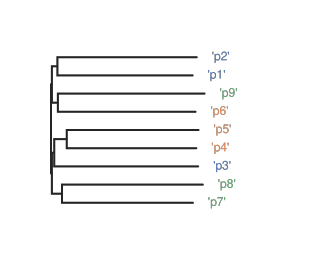

generation-02: grupos do DAMICORE = [[1, 2, 9], [3, 6], [4, 5], [7, 8]]


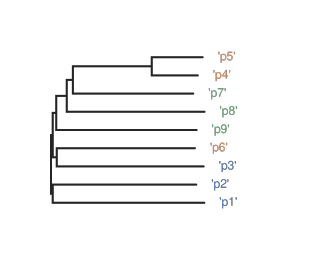

generation-03: grupos do DAMICORE = [[4], [5], [1, 2], [3], [6, 8], [7, 9]]


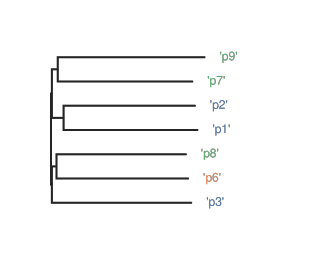

generation-04: grupos do DAMICORE = [[4], [5], [1, 2], [3, 6], [7, 8, 9]]


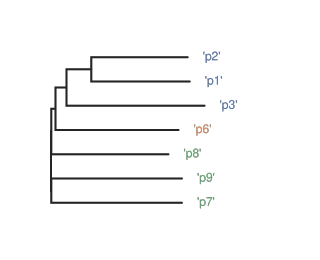

generation-05: grupos do DAMICORE = [[4], [5], [1, 2, 3], [6, 8], [7, 9]]


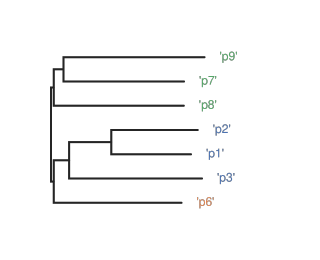

In [3]:
example_dir = output_dir / "example"
codon_of = {f"p{p + 1}": c for c, members in enumerate(CODONS) for p in members}
colors_by_codon = ["#4c72b0", "#dd8452", "#55a868"]
for generation_dir in sorted(example_dir.glob("generation-*")):
    groups = json.loads((generation_dir / "groups.json").read_text(encoding="utf-8"))
    if not (generation_dir / "tree.nwk").exists():
        print(f"{generation_dir.name}: sem árvore ({groups['damicore_status']}), grupos {groups['groups']}")
        continue
    tree = toytree.tree((generation_dir / "tree.nwk").read_text(encoding="utf-8"))
    colors = [colors_by_codon[codon_of[name.strip("'")]] for name in tree.get_tip_labels()]
    print(f"{generation_dir.name}: grupos do DAMICORE = {groups['groups']}")
    canvas, _, _ = tree.draw(width=320, height=260, tip_labels_colors=colors)
    display(canvas)


## 2. Ele otimiza?

Cada linha fina é uma execução; a linha grossa é a mediana. A faixa vermelha é o
top 70 (as 70 melhores de 261 mil sequências).


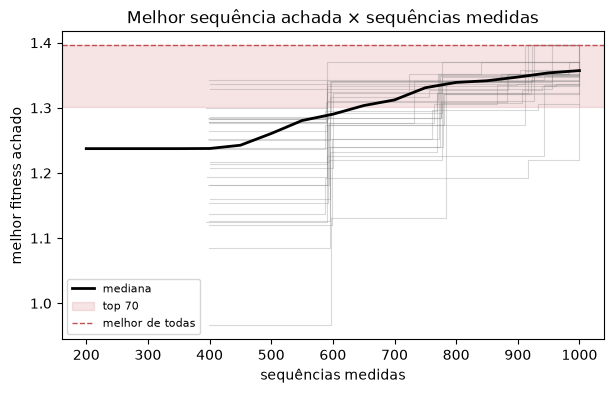

Chegaram ao top 70: 100% das execuções
Acharam a melhor de todas (AAGGAAATG): 27%
Em média o melhor achado vale 97.6% do máximo
Mediana de sequências medidas até entrar no top 70: 766


,seed,best_fitness,best_sequence,share_of_optimum,reached_top,found_optimum,evaluations_to_top,generations
0,1,1.349993,CGTGAAATG,0.967188,True,False,773,5
1,2,1.352514,ACTGACCAG,0.968994,True,False,589,11
2,3,1.395792,AAGGAAATG,1.000000,True,True,600,5
3,4,1.395792,AAGGAAATG,1.000000,True,True,732,6
4,5,1.371104,CTGGAAATG,0.982313,True,False,591,8
5,6,1.395792,AAGGAAATG,1.000000,True,True,400,8
6,7,1.349993,CGTGAAATG,0.967188,True,False,772,5
7,8,1.352514,ACTGACCAG,0.968994,True,False,776,10
8,9,1.336947,GTCGACCAA,0.957841,True,False,764,9
9,10,1.335049,TACGACCAA,0.956481,True,False,942,5


In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
for _, run in generations.groupby("seed"):
    ax.step(run["evaluations"], run["best_fitness"], where="post", color="grey", alpha=0.3, lw=0.8)
grid = np.arange(200, DEFAULT_CONFIG.budget + 1, 50)
curves = [np.interp(grid, run["evaluations"], run["best_fitness"]) for _, run in generations.groupby("seed")]
ax.plot(grid, np.median(curves, axis=0), color="black", lw=2, label="mediana")
ax.axhspan(audit["top_threshold"], audit["optimum"]["fitness"], color="#c44e52", alpha=0.15, label="top 70")
ax.axhline(audit["optimum"]["fitness"], color="#c44e52", lw=1, ls="--", label="melhor de todas")
ax.set(xlabel="sequências medidas", ylabel="melhor fitness achado",
       title="Melhor sequência achada × sequências medidas")
ax.legend(fontsize=8)
plt.show()

print(f"Chegaram ao top 70: {audit['reached_top_share']:.0%} das execuções")
print(f"Acharam a melhor de todas ({audit['optimum']['sequence']}): {audit['found_optimum_share']:.0%}")
print(f"Em média o melhor achado vale {audit['mean_share_of_optimum']:.1%} do máximo")
print(f"Mediana de sequências medidas até entrar no top 70: {audit['median_evaluations_to_top']:.0f}")
display(runs.head(10))


## 3. O DAMICORE achou os códons?

Para cada par de posições contamos: em quantas das gerações o DAMICORE colocou
as duas no mesmo grupo? Os quadrados pretos marcam os três códons. Se o DAMICORE
enxerga códons, os números altos ficam dentro dos quadrados.


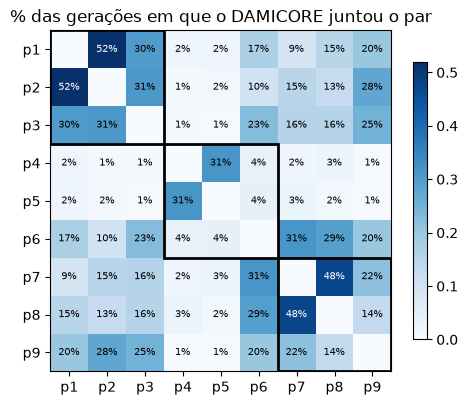

,par,mesmo códon?,juntos,epistasia real
0,1-2,True,52%,0.035
1,7-8,True,48%,0.267
2,6-7,False,31%,0.011
3,4-5,True,31%,0.012
4,2-3,True,31%,0.005
5,1-3,True,30%,0.013
6,6-8,False,29%,0.147
7,2-9,False,28%,0.001


In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(frequency.to_numpy(), cmap="Blues", vmin=0)
for (i, j), value in np.ndenumerate(frequency.to_numpy()):
    if i != j:
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
                color="white" if value > 0.35 else "black")
for start in (0, 3, 6):
    ax.add_patch(plt.Rectangle((start - 0.5, start - 0.5), 3, 3, fill=False, lw=2, color="black"))
ax.set_xticks(range(9), frequency.columns)
ax.set_yticks(range(9), frequency.index)
ax.set_title("% das gerações em que o DAMICORE juntou o par")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

display(pairs.head(8).assign(
    grouped_share=lambda d: d["grouped_share"].map("{:.0%}".format),
    epistasis=lambda d: d["epistasis"].round(3),
).rename(columns={"pair": "par", "same_codon": "mesmo códon?", "grouped_share": "juntos", "epistasis": "epistasia real"}))


### Os códons são uma divisão especial, ou qualquer divisão daria igual?

Existem **280** jeitos de dividir 9 posições em 3 trincas. Para cada um medimos
"quanto o DAMICORE junta dentro das trincas" menos "quanto junta entre trincas".
Se o DAMICORE não visse nada de códon, a divisão em códons cairia no meio da
pilha. O valor-p é a fração das 280 divisões que ficam empatadas ou acima dos
códons; não depende de nenhuma suposição estatística.


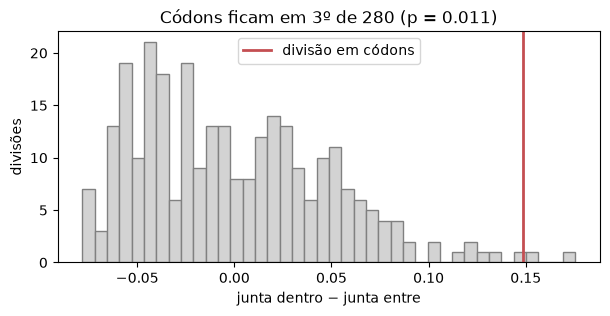

1º: 1-2-3 | 4-5-9 | 6-7-8   contraste 0.176
2º: 1-2-9 | 3-4-5 | 6-7-8   contraste 0.156
3º: 1-2-3 | 4-5-6 | 7-8-9   contraste 0.148


In [6]:
values = frequency.to_numpy()
contrasts = np.array([_codon_contrast(values, p) for p in _triple_partitions()])
test = audit["codon_test"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(contrasts, bins=40, color="lightgrey", edgecolor="grey")
ax.axvline(test["codon_contrast"], color="#c44e52", lw=2, label="divisão em códons")
ax.set(xlabel="junta dentro − junta entre", ylabel="divisões",
       title=f"Códons ficam em {test['codon_rank']}º de {test['partitions']} (p = {test['p_value']:.3f})")
ax.legend()
plt.show()
best = sorted(_triple_partitions(), key=lambda p: -_codon_contrast(values, p))[:3]
for rank, partition in enumerate(best, start=1):
    print(f"{rank}º: " + " | ".join("-".join(str(q + 1) for q in trio) for trio in partition)
          + f"   contraste {_codon_contrast(values, partition):.3f}")


## 4. Bate com o que o dado mostra?

Códon é a explicação biológica; o dado em si mostra outra coisa que podemos medir
direto: **epistasia**, ou seja, quanto o efeito de uma letra depende da letra de
outra posição. Calculamos isso com as 261 mil medidas (entre as sequências que
crescem), algo que o AED **nunca** vê: ele só mede 1.000. Cada ponto abaixo é
um par de posições.


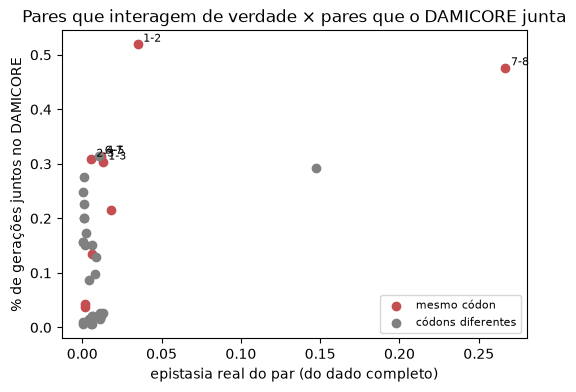

Correlação de Spearman (36 pares): 0.22 (p = 0.19)


,p1,p2,p3,p4,p5,p6,p7,p8,p9
p1,0.000,0.035,0.013,0.006,0.006,0.003,0.004,0.001,0.001
p2,0.035,0.000,0.005,0.005,0.004,0.008,0.006,0.009,0.001
p3,0.013,0.005,0.000,0.000,0.000,0.001,0.000,0.000,0.001
p4,0.006,0.005,0.000,0.000,0.012,0.002,0.012,0.013,0.006
p5,0.006,0.004,0.000,0.012,0.000,0.002,0.011,0.011,0.006
p6,0.003,0.008,0.001,0.002,0.002,0.000,0.011,0.147,0.001
p7,0.004,0.006,0.000,0.012,0.011,0.011,0.000,0.267,0.018
p8,0.001,0.009,0.000,0.013,0.011,0.147,0.267,0.000,0.006
p9,0.001,0.001,0.001,0.006,0.006,0.001,0.018,0.006,0.000


In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for same, color, label in ((True, "#c44e52", "mesmo códon"), (False, "grey", "códons diferentes")):
    part = pairs.loc[pairs["same_codon"] == same]
    ax.scatter(part["epistasis"], part["grouped_share"], color=color, label=label)
for _, row in pairs.head(6).iterrows():
    ax.annotate(row["pair"], (row["epistasis"], row["grouped_share"]), fontsize=8,
                xytext=(4, 2), textcoords="offset points")
ax.set(xlabel="epistasia real do par (do dado completo)", ylabel="% de gerações juntos no DAMICORE",
       title="Pares que interagem de verdade × pares que o DAMICORE junta")
ax.legend(fontsize=8)
plt.show()
spearman = audit["grouped_share_vs_epistasis_spearman"]
print(f"Correlação de Spearman (36 pares): {spearman['rho']:.2f} (p = {spearman['p_value']:.2f})")
display(epistasis.round(3))


## 5. O que dá para dizer

- **Otimiza.** Medindo 0,4% das sequências, todas as execuções chegaram ao top 70
  (0,03% melhores) e cerca de um quarto achou a melhor de todas.
- **O DAMICORE acha os códons sem ninguém contar.** Os dois pares que ele mais
  junta (1-2 e 7-8) são do mesmo códon, 4-5 vem logo depois, e a divisão em
  códons fica entre as 3 melhores de 280 (p ≈ 0,01). A melhor de todas,
  1-2-3 | 4-5-9 | 6-7-8, difere dos códons só por trocar 6 e 9.
- **E o par mais forte do dado é o que ele vê.** 7-8 é de longe o par com mais
  epistasia real e está entre os que o DAMICORE mais junta; 6-8 (o segundo mais
  forte, entre códons vizinhos) também aparece alto. Isso sugere que ele não acha
  "códon" por acaso: acha as posições que de fato interagem.

**Limites (para contar ao professor sem esconder):**

- A correlação geral entre "o DAMICORE junta" e "epistasia real" nos 36 pares é
  fraca e não significativa: ele acerta os pares fortes, mas junta também alguns
  pares sem interação (por exemplo 2-9, 3-9), porque com 60 promissoras uma
  coincidência de letras já parece parentesco.
- O códon do meio (4-5-6) aparece como 4-5 separado do resto; a posição 6 anda
  mais com 7-8, o que bate com a epistasia 6-8 do dado, mas não com a trinca.
- O problema é pequeno (9 posições): um algoritmo que trata cada posição sozinha
  também chega ao topo. O ponto aqui não é ganhar de alguém; é mostrar que o
  modelo que o DAMICORE monta tem significado biológico.
- Sequências não medidas (811) contam como mortas.
